## Dependencias

In [1]:
import joblib
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

## Parámetros

In [2]:
SEED = 42

## Lectura de conjuntos de datos procesados

In [3]:
X_train_final = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\X_train_final.xlsx", index_col = 0)

In [4]:
X_test_final = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\X_test_final.xlsx", index_col = 0)

In [5]:
y_train = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\y_train.xlsx", index_col = 0).squeeze("columns")

In [6]:
# Tuve que utilizar Squeeze para que me traiga los datos de "y_train" como una Serie de pandas, y no como un DataFrame
# Si no lo hago, Random Forest da un error, ya que espera una serie de pandas para la variable "y".

In [7]:
y_test = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\y_test.xlsx", index_col = 0).squeeze("columns")

In [8]:
X_test_final

,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),systolic,relaxation,...,Urine protein,serum creatinine,AST,ALT,Gtp,dental caries,gender_F,gender_M,tartar_N,tartar_Y
28092,30,175,80,3.750000,0.041667,0.041667,0.041667,0.041667,4.708333,3.333333,...,0.041667,0.006250,0.666667,1.125000,2.166667,1,0,1,0,1
46589,60,165,65,3.541667,0.005556,0.041667,0.041667,0.041667,5.166667,3.416667,...,0.041667,0.041667,0.916667,1.041667,1.083333,0,0,1,0,1
130,45,160,55,3.250000,0.041667,0.041667,0.041667,0.041667,5.333333,3.666667,...,0.041667,0.004861,1.125000,0.583333,0.916667,1,1,0,0,1
33481,40,155,50,3.166667,0.005556,0.043056,0.041667,0.041667,4.583333,2.708333,...,0.041667,0.004167,1.041667,0.875000,1.166667,1,1,0,0,1
34477,45,160,50,2.750000,0.043056,0.041667,0.041667,0.041667,4.166667,2.500000,...,0.041667,0.006250,0.875000,0.500000,0.791667,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27265,35,180,75,3.045833,0.041667,0.043056,0.041667,0.041667,4.583333,2.500000,...,0.041667,0.043750,0.833333,0.875000,0.583333,0,0,1,0,1
47956,20,165,55,3.208333,0.043056,0.045139,0.041667,0.041667,5.000000,3.333333,...,0.041667,0.041667,1.125000,0.708333,1.291667,0,0,1,1,0
22181,50,175,75,3.791667,0.003472,0.002083,0.041667,0.041667,5.000000,3.250000,...,0.041667,0.006250,1.000000,0.458333,2.833333,1,0,1,0,1
27516,35,170,65,3.250000,0.006250,0.006250,0.041667,0.041667,4.916667,3.541667,...,0.041667,0.006250,3.333333,2.416667,1.708333,0,0,1,0,1


In [9]:
y_test

28092    1
46589    0
130      1
33481    0
34477    0
        ..
27265    0
47956    1
22181    1
27516    1
9154     0
Name: smoking, Length: 15000, dtype: int64

## Modelo Arbol de decisión

In [10]:
clf_dtc = DecisionTreeClassifier(max_depth = 3, random_state = SEED)

In [11]:
clf_dtc

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [12]:
%%time
clf_dtc.fit(X_train_final, y_train)

CPU times: total: 141 ms
Wall time: 154 ms


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [13]:
%%time
train_pred_dtc = clf_dtc.predict(X_train_final)
test_pred_dtc = clf_dtc.predict(X_test_final)

CPU times: total: 15.6 ms
Wall time: 17.8 ms


In [14]:
print("Train_Arbol_de_Decisión")
print(classification_report(y_train, train_pred_dtc))
print("--------------------------------------------------------")
print("Test_Arbol_de_Decisión")
print(classification_report(y_test, test_pred_dtc))

Train_Arbol_de_Decisión
              precision    recall  f1-score   support

           0       0.81      0.75      0.78     22170
           1       0.62      0.70      0.66     12830

    accuracy                           0.73     35000
   macro avg       0.72      0.72      0.72     35000
weighted avg       0.74      0.73      0.74     35000

--------------------------------------------------------
Test_Arbol_de_Decisión
              precision    recall  f1-score   support

           0       0.81      0.75      0.78      9501
           1       0.62      0.69      0.65      5499

    accuracy                           0.73     15000
   macro avg       0.71      0.72      0.71     15000
weighted avg       0.74      0.73      0.73     15000



In [15]:
y_train

8319     1
7833     0
27390    0
44413    1
24218    0
        ..
48892    0
25727    0
18911    0
25680    0
43737    1
Name: smoking, Length: 35000, dtype: int64

In [16]:
joblib.dump(clf_dtc, r"C:\Users\Morena\TP2\objects\models\modelo_arbol_decision.pkl")

['C:\\Users\\Morena\\TP2\\objects\\models\\modelo_arbol_decision.pkl']

## Modelo Random Forest

In [17]:
clf_rf = RandomForestClassifier(n_estimators = 137, max_depth=31, min_samples_split = 5, min_samples_leaf =300, random_state=SEED)

In [18]:
%%time
clf_rf.fit(X_train_final, y_train)

CPU times: total: 3.22 s
Wall time: 3.22 s


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",137
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",31
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [19]:
y_train.info()

<class 'pandas.Series'>
Index: 35000 entries, 8319 to 43737
Series name: smoking
Non-Null Count  Dtype
--------------  -----
35000 non-null  int64
dtypes: int64(1)
memory usage: 546.9 KB


In [20]:
y_train

8319     1
7833     0
27390    0
44413    1
24218    0
        ..
48892    0
25727    0
18911    0
25680    0
43737    1
Name: smoking, Length: 35000, dtype: int64

In [21]:
%%time
train_pred_rf = clf_rf.predict(X_train_final)
test_pred_rf = clf_rf.predict(X_test_final)

CPU times: total: 438 ms
Wall time: 429 ms


In [22]:
print("Train Random Forest")
print(classification_report(y_train, train_pred_rf))
print("--------------------------------------------------------")
print("Test Random Forest")
print(classification_report(y_test, test_pred_rf))

Train Random Forest
              precision    recall  f1-score   support

           0       0.83      0.77      0.80     22170
           1       0.65      0.73      0.69     12830

    accuracy                           0.76     35000
   macro avg       0.74      0.75      0.75     35000
weighted avg       0.77      0.76      0.76     35000

--------------------------------------------------------
Test Random Forest
              precision    recall  f1-score   support

           0       0.82      0.77      0.79      9501
           1       0.64      0.72      0.68      5499

    accuracy                           0.75     15000
   macro avg       0.73      0.74      0.73     15000
weighted avg       0.76      0.75      0.75     15000



In [23]:
joblib.dump(clf_rf, r"C:\Users\Morena\TP2\objects\models\modelo_random_forest.pkl")

['C:\\Users\\Morena\\TP2\\objects\\models\\modelo_random_forest.pkl']

## XGBoost

In [24]:
clf_xgb = XGBClassifier(n_estimators = 300, learning_rate = 0.02, max_depth = 3, random_state=SEED)

In [25]:
%%time
clf_xgb.fit(X_train_final, y_train)

CPU times: total: 3.66 s
Wall time: 500 ms


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [26]:
%%time
train_pred_xgb = clf_xgb.predict(X_train_final)
test_pred_xgb = clf_xgb.predict(X_test_final)

CPU times: total: 281 ms
Wall time: 73.2 ms


In [27]:
train_pred_xgb

array([1, 0, 0, ..., 0, 0, 1], shape=(35000,))

In [28]:
print("Train XGB")
print(classification_report(y_train, train_pred_xgb))
print("--------------------------------------------------------")
print("Test XGB")
print(classification_report(y_test, test_pred_xgb))

Train XGB
              precision    recall  f1-score   support

           0       0.84      0.78      0.81     22170
           1       0.66      0.73      0.70     12830

    accuracy                           0.77     35000
   macro avg       0.75      0.76      0.75     35000
weighted avg       0.77      0.77      0.77     35000

--------------------------------------------------------
Test XGB
              precision    recall  f1-score   support

           0       0.83      0.78      0.80      9501
           1       0.66      0.72      0.69      5499

    accuracy                           0.76     15000
   macro avg       0.74      0.75      0.75     15000
weighted avg       0.76      0.76      0.76     15000



In [29]:
%%time
train_pred_proba_xgb = clf_xgb.predict_proba(X_train_final)[:,1]
test_pred_proba_xgb = clf_xgb.predict_proba(X_test_final)[:,1]

CPU times: total: 297 ms
Wall time: 67.2 ms


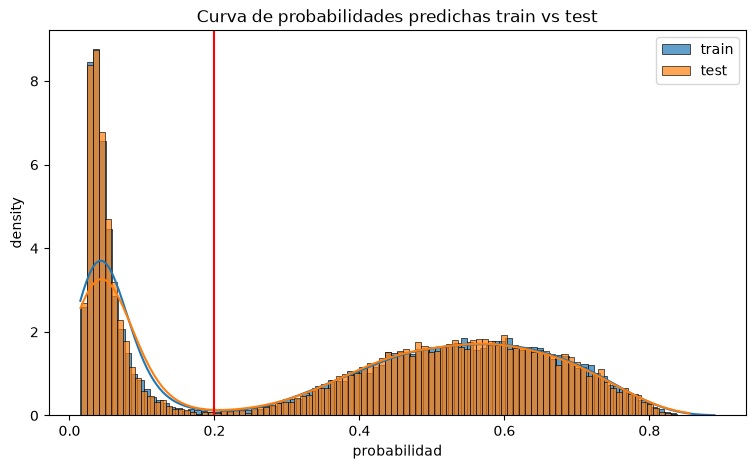

In [30]:
plt.figure(figsize=(9,5))
sns.histplot(train_pred_proba_xgb, bins=100, kde=True, label="train", stat="density", alpha=0.7)
sns.histplot(test_pred_proba_xgb, bins=100, kde=True, label="test", stat="density", alpha=0.7)
plt.axvline(0.2, color="red")
plt.title("Curva de probabilidades predichas train vs test")
plt.xlabel("probabilidad")
plt.ylabel("density")
plt.legend()
plt.show()

In [31]:
joblib.dump(clf_xgb, r"C:\Users\Morena\TP2\objects\models\modelo_XGBoost.pkl")

['C:\\Users\\Morena\\TP2\\objects\\models\\modelo_XGBoost.pkl']

In [32]:
threshold = 0.435

In [33]:
y_train_pred_custom_xgb = (train_pred_proba_xgb >= threshold).astype(int)
y_test_pred_custom_xgb = (test_pred_proba_xgb >= threshold).astype(int)

In [34]:
print("Train XGB Proba Custom")
print(classification_report(y_train, y_train_pred_custom_xgb))
print("--------------------------------------------------------")
print("Test XGB Proba Custom")
print(classification_report(y_test, y_test_pred_custom_xgb))

Train XGB Proba Custom
              precision    recall  f1-score   support

           0       0.89      0.70      0.78     22170
           1       0.62      0.86      0.72     12830

    accuracy                           0.75     35000
   macro avg       0.76      0.78      0.75     35000
weighted avg       0.79      0.75      0.76     35000

--------------------------------------------------------
Test XGB Proba Custom
              precision    recall  f1-score   support

           0       0.89      0.69      0.78      9501
           1       0.62      0.85      0.71      5499

    accuracy                           0.75     15000
   macro avg       0.75      0.77      0.75     15000
weighted avg       0.79      0.75      0.76     15000



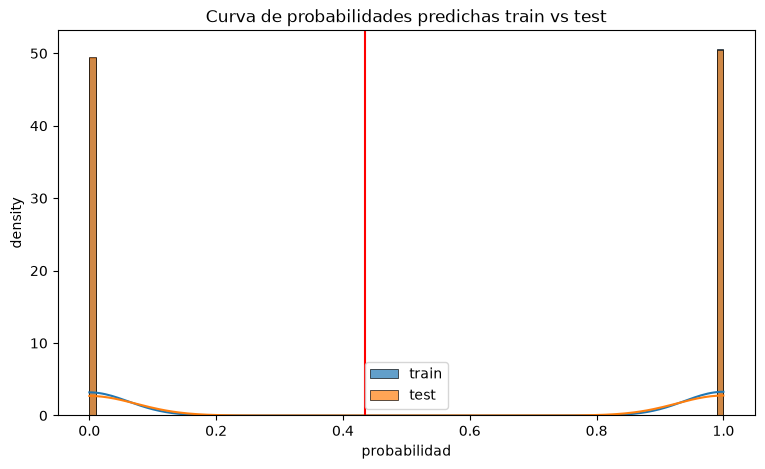

In [35]:
plt.figure(figsize=(9,5))
sns.histplot(y_train_pred_custom_xgb, bins=100, kde=True, label="train", stat="density", alpha=0.7)
sns.histplot(y_test_pred_custom_xgb, bins=100, kde=True, label="test", stat="density", alpha=0.7)
plt.axvline(threshold, color="red")
plt.title("Curva de probabilidades predichas train vs test")
plt.xlabel("probabilidad")
plt.ylabel("density")
plt.legend()
plt.show()